# ZADANIE 1

a) Wykonaj poniższy skrypt i przeanalizuj go:

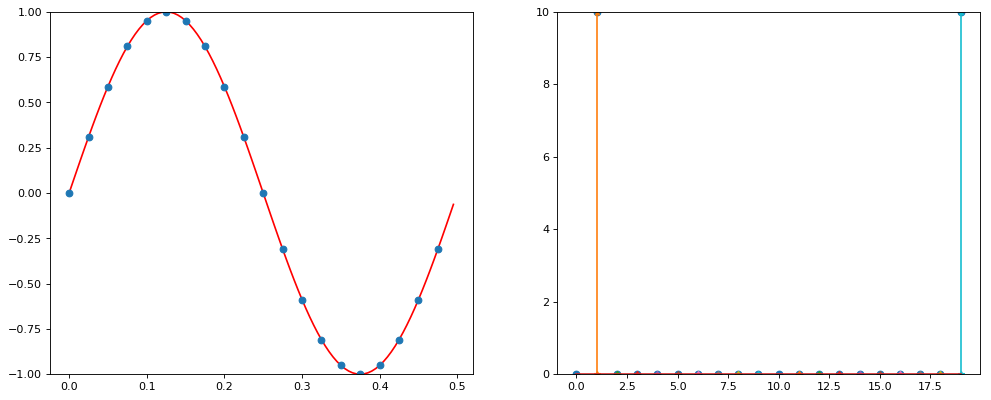

In [ ]:
from __future__ import division
from pylab import *
from numpy import *
from scipy import *
from ipywidgets import *
import math as mt

%matplotlib inline

A = 1
# Amplituda sygnału

LP = 1
# Liczba analizowanych pełnych przebiegów sygnału (okresów)
w = 40
# częstotliwość probkowania [Hz] sygnału
#(jak często w ciągu sekundy pobieramy informacje o wartości sygnału)

f = 2.0
# Czestotliwosc sygnalu [Hz]

T = 1.0/f
# Okres sygnalu [s] (jak długo trwa jeden przebieg sinusa)

TW = 1.0/w
# Okres probkowania [s] (co ile sekund pobieramy próbkę)

t = np.arange(0, LP*T, TW)
# generujemy momenty, w których pobieramy próbki

n = len(t)

FUNC = lambda t : A*sin(2*pi*t*f)
# def. funkcji (tutaj sinus)

signal = FUNC(t)
# funkcja sprobkowana

fig = plt.figure(figsize=(15, 6), dpi=80)
ax = fig.add_subplot(121)
## --- POMOCNICZY SYGNAL
base_t = np.arange(0, LP*T, 1.0/200.0)
base_signal = FUNC(base_t)
ax.plot(base_t, base_signal, linestyle='-', color='red')
ax.set_ylim([min(base_signal), max(base_signal)])
## ---
ax.plot(t, signal, 'o')

signal1 = fft(signal)
# sygnal w dziedzinie czestotliwosci
signal1 = abs(signal1)
# modul sygnalu

freqs = range(int(n))


ax = fig.add_subplot(122)
ymax = max(signal1)
if (ymax > 3.0):
    ax.set_ylim([0.0,ymax])
else:
    ax.set_ylim([0.0,3.0])
stem(freqs, signal1, '-*')

show()

UWAGA: do dalszych ćwiczeń warto powyższy skrypt przekształcić na funkcję o wielu argumentach, typu: amplituda, częstotliwość próbkowania, liczba przebiegów. Oczywiście dla wygody, należy nadać wartości domyślne argumentom funkcji.

In [ ]:
# Zdefiniuj funkcję
import numpy as np
import matplotlib.pyplot as plt

def signal_analysis(A=1.0, f=1.0, w=100.0, LP=10):
    T = 1.0 / f
    TW = 1.0 / w
    t = np.arange(0, LP * T, TW)
    n = len(t)
     
    signal = A * np.sin(2 * np.pi * f * t)
    
    fig = plt.figure(figsize=(15, 6), dpi=80)
    ax1 = fig.add_subplot(121)
    ax1.plot(t, signal, 'o-')
    ax1.set_xlabel('Time [s]')
    ax1.set_ylabel('Amplitude')
    ax1.set_title('Time Domain Signal')

    signal_fft = np.fft.fft(signal)
    signal_fft_abs = np.abs(signal_fft)
    signal_fft_scaled = signal_fft_abs * 2 / n
    freqs = np.arange(n) * (w / n)

    ax2 = fig.add_subplot(122)
    half_n = n // 2
    ax2.stem(freqs[:half_n], signal_fft_scaled[:half_n], '-*')
    ax2.set_xlabel('Frequency [Hz]')
    ax2.set_ylabel('Magnitude')
    ax2.set_title('Frequency Domain Signal')
    ax2.set_ylim([0, A + 0.5])

    plt.show()

signal_analysis(A=1.0, f=1.0, w=50.0, LP=5)

: 

UWAGA DLA CHĘTNYCH: można wykorzystać 'interact', dzięki któremu można zmieniac parametry danej funkcji i na bieżąco obserwować zmiany. Poniższy kod przedstawia sposób wykorzystania interact:

In [ ]:
from ipykernel.pylab.backend_inline import flush_figures

def prosta(a=2, b=0):
    x = linspace(-5, 5, 100, endpoint=False) # punkty na osi OX [s]
    f = lambda x : a*x + b
    y = f(x)

    fig = plt.figure(figsize=(6, 3), dpi=80)
    ax = fig.add_subplot(111)
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.plot(x, y)
    flush_figures()

interact(prosta, a=(-5,5,0.5), b=(-5,5,0.5))


b) Zmień częstotliwość próbkowania na 50Hz.

In [ ]:
# w=50
signal_analysis(A=1.0, f=1.0, w=50.0, LP=5)

c) Punkty na osi OX spektrum są teraz kolejnymi liczbami naturalnymi, a nie częstotliwościami w Hz. Popraw skrypt (funkcje), tak aby oś OX spektrum była w Hz (podpowiedź: oś OX rozpoczyna się od 0Hz, a kończy się na (prawie!)  Hz, gdzie  jest częstotliwością próbkowania). Następnie: Upewnij się, że spektrum dla 1Hz-owego sinusa i pięciu (LP=5) analizowanych przebiegów wygląda teraz prawidłowo.

In [ ]:
# popraw oś OX

# Oś poprawiona jest w głównej funkcji signal_analysis: frreqs = np.arange(n) * (w / n)

d) Podpisz osie obu wykresów, używając funkcji xlabel() i ylabel(). Pamiętaj o jednostkach.

In [ ]:
# Podpisz osie wykresów

# Osie podpisane są w głównej funkcji signal_analysis
# ax1.set_xlabel('Time [s]'), ax1.set_ylabel('Amplitude')
# ax2.set_xlabel('Frequency [Hz]'), ax2.set_ylabel('Magnitude')

f) Porównaj spektrum funkcji $sin(2*pi*f*t)$, $2*sin(2*pi*f*t)$ i $3*sin(2*pi*f*t)$. Jak zmienia się wartość na osi OY na wykresie spektrum?

In [ ]:
# f=1, A=1, LP=1
signal_analysis(A=1.0, f=1.0, w=50.0, LP=1)

In [ ]:
# f=1, A=2, LP=1
signal_analysis(A=2.0, f=1.0, w=50.0, LP=1)

In [ ]:
# f=1, A=3, LP=1
signal_analysis(A=3.0, f=1.0, w=50.0, LP=1)

g) Ile punktów jest na wykresach przy częstotliwości próbkowania 50Hz, T=1s? Zwiększ dwukrotnie liczbę próbek poprzez zwiększenie częstotliwości próbkowania. Następnie: dla $sin(2*pi*f*t)$ porównaj wartość na osi OY spektrum uzyskane w tym oraz poprzednim punkcie.

In [ ]:
# f=1, w=50, LP=1
signal_analysis(A=1.0, f=1.0, w=50.0, LP=1)

In [ ]:
# f=1, w=100, LP=1
signal_analysis(A=1.0, f=1.0, w=100.0, LP=1)

h) Na podstawie wyników uzyskanych w dwóch poprzednich punktach przeskaluj oś OY spektrum tak, aby wskazywała wartości amplitud badanych sygnałów. Sprawdź wyniki dla kilku wybranych funkcji.

In [ ]:
# popraw oś OY

# Oś Y poprawiona jest w głównej funkcji signal_analysis: signal_fft_scaled = signal_fft_abs * 2 / n

# Zadanie 2

Plik spots.txt zawiera wartości aktywności Słońca w kolejnych miesiącach. Wykreśl ten sygnał oraz jego spektrum. Za pomocą FFT, oblicz częstotliwość cyklu aktywności słonecznej.

# Zadanie 3

Wykreśl sygnał $sin(2*pi*t) + sin(4*pi*t)$, T=1s, w=20Hz. Za pomocą FFT, przekształć sygnał do dziedziny częstotliwości. Następnie usuń składowe o częstotliwości 2Hz. Tak zmodyfikowany sygnał przekształć do dziedziny czasu i wykreśl go.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

T = 1.0
w = 20.0
TW = 1.0 / w
t = np.arange(0, T, TW)
n = len(t)

signal = np.sin(2*np.pi*t) + np.sin(4*np.pi*t)
signal_fft = np.fft.fft(signal)
freqs = np.arange(n) * (w / n)

signal_fft_filtered = signal_fft.copy()
for i in range(n):
    if np.isclose(freqs[i], 2.0) or np.isclose(freqs[i], w - 2.0):
        signal_fft_filtered[i] = 0

signal_filtered = np.real(np.fft.ifft(signal_fft_filtered))

fig, axs = plt.subplots(3, 1, figsize=(10, 12))

axs[0].plot(t, signal, 'o-', color='blue')
axs[0].set_title('Original Signal: sin(2pit) + sin(4pit)')
axs[0].set_xlabel('Time [s]')
axs[0].grid(True)

half_n = n // 2
axs[1].stem(freqs[:half_n], np.abs(signal_fft)[:half_n] * 2 / n, '-*')
axs[1].set_title('FFT of Original Signal')
axs[1].set_xlabel('Frequency [Hz]')
axs[1].grid(True)

axs[2].plot(t, signal_filtered, 'o-', color='green')
axs[2].set_title('Filtered Signal')
axs[2].set_xlabel('Time [s]')
axs[2].grid(True)

plt.tight_layout()
plt.show()

# Zadanie 4

Wczytaj plik err.wav. Wykreśl jego spektrum. Spróbuj także skali logarytmicznej. Określ dominujące w sygnale częstotliwości.